# Marketing Campaigns — Course-End Project

This notebook follows the actions listed in the supplied Marketing Campaigns problem statement. It contains only the requested data preparation, variable creation, distributions and outlier treatment, encoding, correlation, hypothesis testing, and visualizations.

## 1. Data Import

In [1]:
!mamba install pandas numpy matplotlib seaborn scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.976 seconds
  Name                Version    Build                Channel
---------------------------------------------------------------------------
+ brotli-python       1.2.0      py313ha26e73d_2      emscripten-forge-4x
+ certifi             2026.7.22  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1      pyhd8ed1ab_0         conda-forge
+ idna                3.20       pyh5ded981_0         conda-forge
+ joblib              1.6.0      py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.27.0     pyh5ded981_0         conda-forge
+ pandas              3.0.6      np23py313h124dbc7_0  emscripten-forge-4x
+ patsy               1.0.3      py313h1804a44_0      emscripten-forge-4x
+ pysocks             1.7.1      py313h1804a44_3      emscripten-forge-4x
+ p

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

sns.set_theme(style="whitegrid")

data = pd.read_csv("marketing_data.csv")

print("Data snapshot:")
display(data.head())

print("Data information:")
data.info()

print("\nMissing values:")
display(data.isnull().sum())

Data snapshot:


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


Data information:
<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   ID                   2240 non-null   int64
 1   Year_Birth           2240 non-null   int64
 2   Education            2240 non-null   str  
 3   Marital_Status       2240 non-null   str  
 4    Income              2216 non-null   str  
 5   Kidhome              2240 non-null   int64
 6   Teenhome             2240 non-null   int64
 7   Dt_Customer          2240 non-null   str  
 8   Recency              2240 non-null   int64
 9   MntWines             2240 non-null   int64
 10  MntFruits            2240 non-null   int64
 11  MntMeatProducts      2240 non-null   int64
 12  MntFishProducts      2240 non-null   int64
 13  MntSweetProducts     2240 non-null   int64
 14  MntGoldProds         2240 non-null   int64
 15  NumDealsPurchases    2240 non-null   int64
 16  NumWebPurchases  

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
 Income                24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

## 2. Investigate Variables

In [5]:
# Remove extra spaces from column names, including the Income column.
data.columns = data.columns.str.strip()

# Convert Income to float after removing currency symbols and commas.
data["Income"] = (
    data["Income"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)
data["Income"] = pd.to_numeric(data["Income"], errors="coerce")

# Convert Dt_Customer to datetime.
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], errors="coerce")

print("Income data type:", data["Income"].dtype)
print("Dt_Customer data type:", data["Dt_Customer"].dtype)
display(data[["Income", "Dt_Customer"]].head())

Income data type: float64
Dt_Customer data type: datetime64[us]


,Income,Dt_Customer
0,84835.0,2014-06-16
1,57091.0,2014-06-15
2,67267.0,2014-05-13
3,32474.0,2014-05-11
4,21474.0,2014-04-08


## 3. Missing Value Imputation

In [6]:
print("Missing values before imputation:")
display(data.isnull().sum())

# Combine similar marital-status categories.
data["Marital_Status"] = data["Marital_Status"].replace({
    "Alone": "Single",
    "YOLO": "Single",
    "Absurd": "Single"
})

# Combine similar education categories.
data["Education"] = data["Education"].replace({
    "2n Cycle": "Master"
})

# Impute missing income using the average income for matching Education and Marital_Status.
data["Income"] = data.groupby(
    ["Education", "Marital_Status"]
)["Income"].transform(lambda x: x.fillna(x.mean()))

# If any income values remain missing because a category has no available mean, use overall mean.
data["Income"] = data["Income"].fillna(data["Income"].mean())

print("Missing values after imputation:")
display(data.isnull().sum())

Missing values before imputation:


ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

Missing values after imputation:


ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
AcceptedCmp3           0
AcceptedCmp4           0
AcceptedCmp5           0
AcceptedCmp1           0
AcceptedCmp2           0
Response               0
Complain               0
Country                0
dtype: int64

## 4. Create Variables

In [7]:
# Calculate age using the current calendar year.
current_year = pd.Timestamp.today().year
data["age"] = current_year - data["Year_Birth"]

# Calculate total spending across product categories.
spending_columns = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]
data["spending"] = data[spending_columns].sum(axis=1)

# Calculate children count and binary has_children.
data["children_count"] = data["Kidhome"] + data["Teenhome"]
data["has_children"] = (data["children_count"] > 0).astype(int)

# Calculate total purchases across purchase channels.
purchase_columns = [
    "NumDealsPurchases", "NumWebPurchases",
    "NumCatalogPurchases", "NumStorePurchases"
]
data["total_purchases"] = data[purchase_columns].sum(axis=1)

display(data[["age", "spending", "children_count", "has_children", "total_purchases"]].head())

,age,spending,children_count,has_children,total_purchases
0,56,1190,0,0,15
1,65,577,0,0,18
2,68,251,1,1,11
3,59,11,2,1,4
4,37,91,1,1,8


## 5. Box Plots, Histograms, and Outlier Treatment

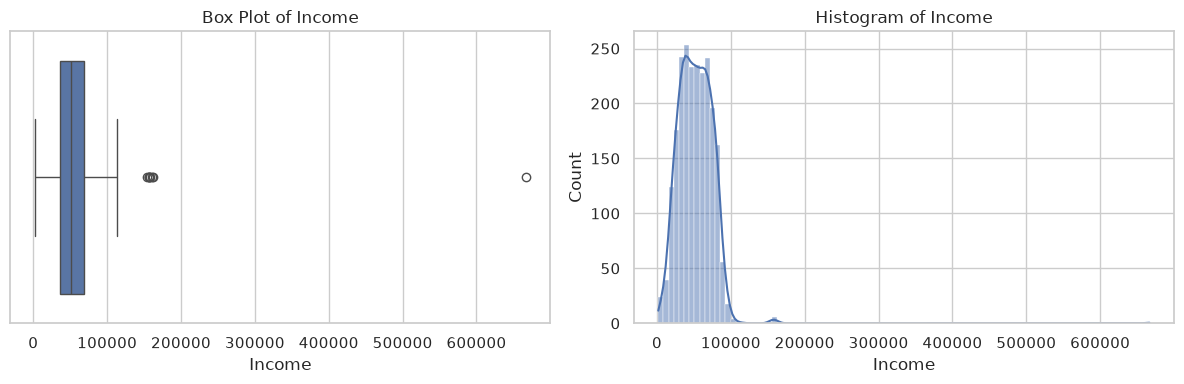

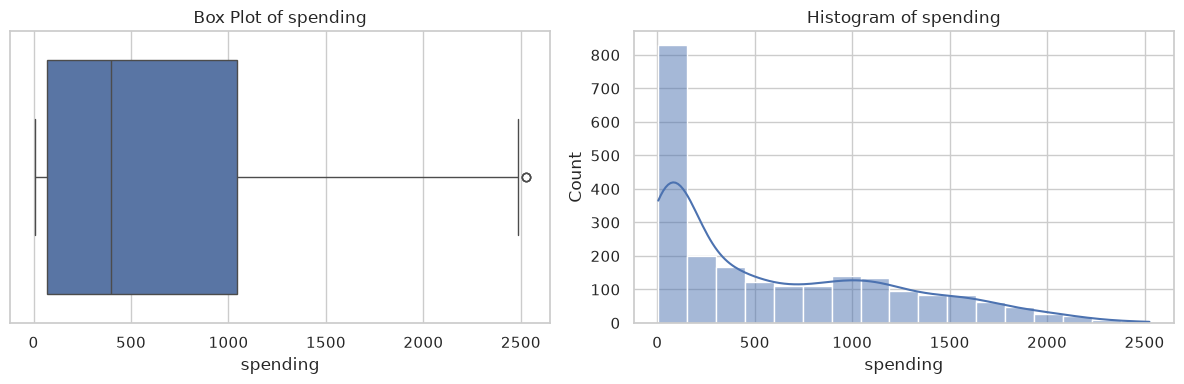

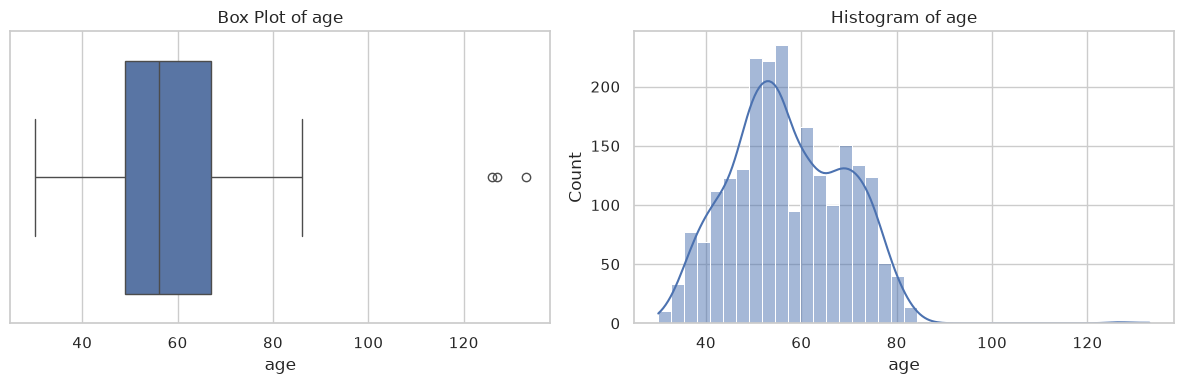

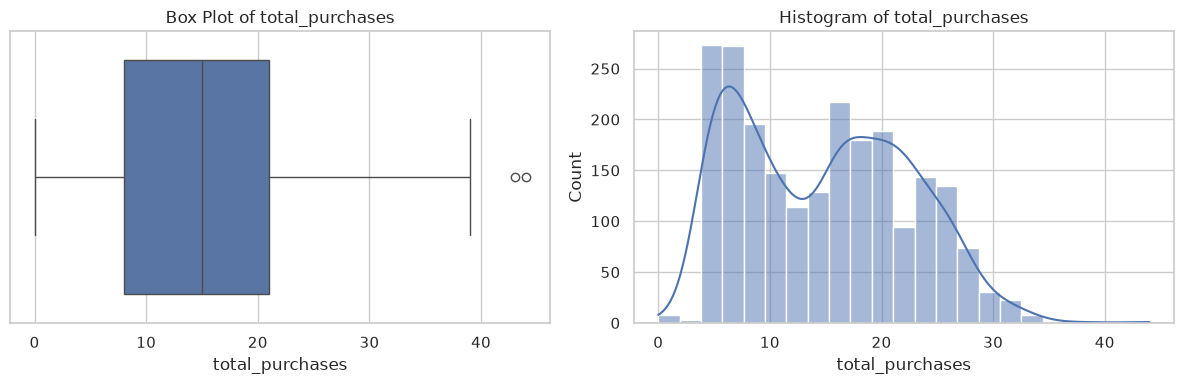

Box plots and histograms after outlier capping:


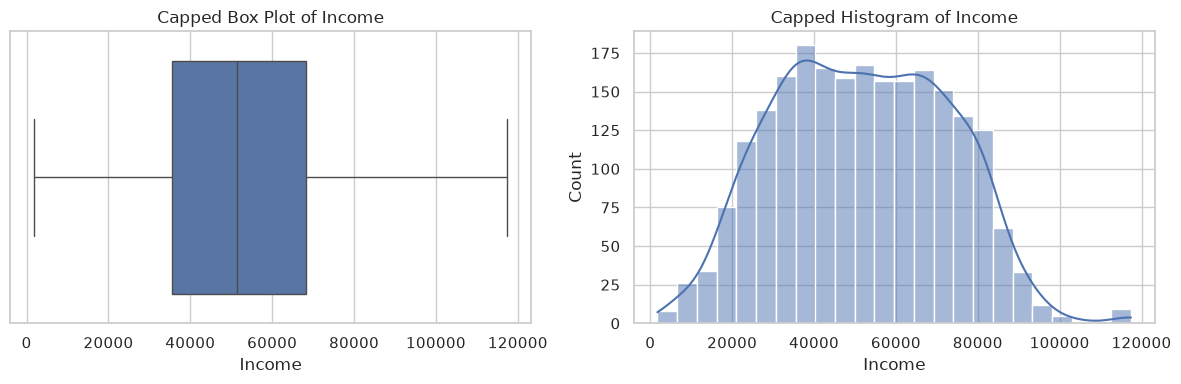

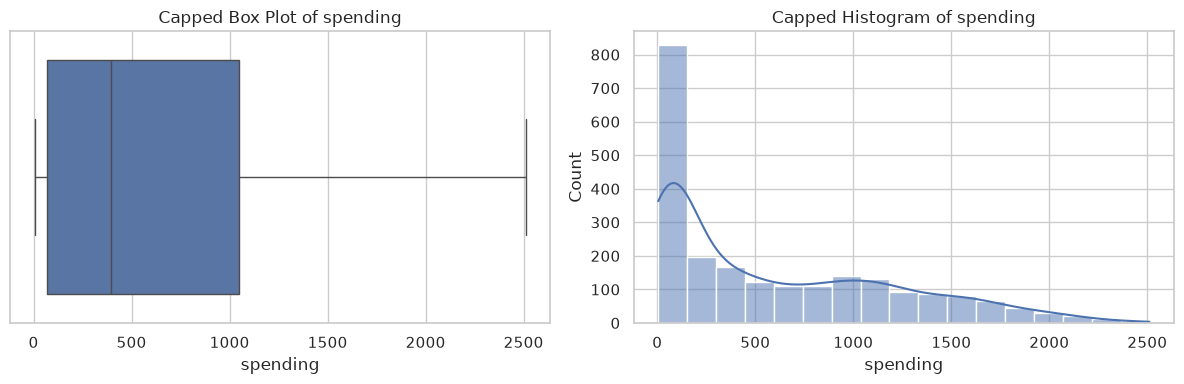

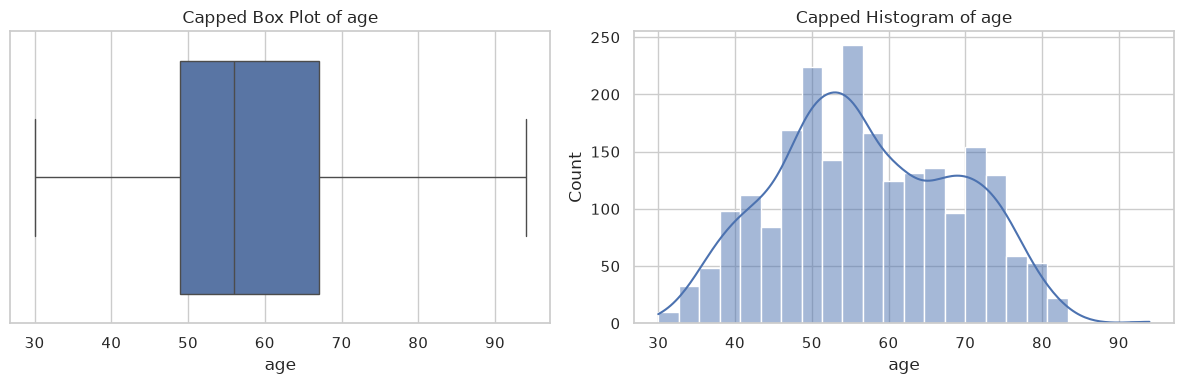

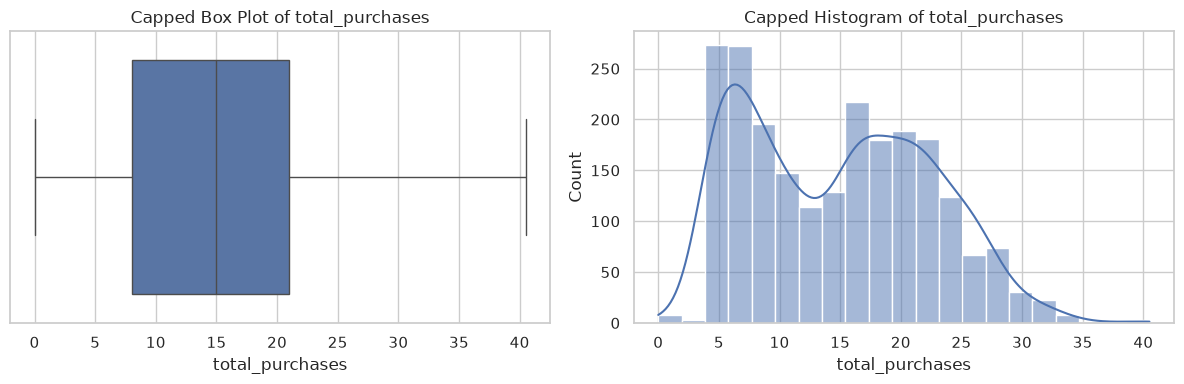

In [8]:
numerical_variables = ["Income", "spending", "age", "total_purchases"]

for column in numerical_variables:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=data[column], ax=axes[0])
    axes[0].set_title(f"Box Plot of {column}")
    sns.histplot(data[column], kde=True, ax=axes[1])
    axes[1].set_title(f"Histogram of {column}")
    plt.tight_layout()
    plt.show()

# Cap outliers to the lower and upper limits (1.5 × IQR rule).
for column in numerical_variables:
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    data[column] = data[column].clip(lower=lower_limit, upper=upper_limit)

print("Box plots and histograms after outlier capping:")
for column in numerical_variables:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=data[column], ax=axes[0])
    axes[0].set_title(f"Capped Box Plot of {column}")
    sns.histplot(data[column], kde=True, ax=axes[1])
    axes[1].set_title(f"Capped Histogram of {column}")
    plt.tight_layout()
    plt.show()

## 6. Encoding

In [9]:
# Ordinal encoding for Education.
education_order = {
    "Basic": 0,
    "Graduation": 1,
    "Master": 2,
    "PhD": 3
}
data["Education"] = data["Education"].map(education_order)

# One-hot encoding for Country and Marital_Status.
new_data = pd.get_dummies(
    data,
    columns=["Country", "Marital_Status"],
    dtype=int
)

display(new_data.head())

,ID,Year_Birth,Education,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,...,Country_IND,Country_ME,Country_SA,Country_SP,Country_US,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,1826,1970,1,84835.0,0,0,2014-06-16,0,189,104,...,0,0,0,1,0,1,0,0,0,0
1,1,1961,1,57091.0,0,0,2014-06-15,0,464,5,...,0,0,0,0,0,0,0,1,0,0
2,10476,1958,1,67267.0,0,1,2014-05-13,0,134,11,...,0,0,0,0,1,0,1,0,0,0
3,1386,1967,1,32474.0,1,1,2014-05-11,0,10,0,...,0,0,0,0,0,0,0,0,1,0
4,5371,1989,1,21474.0,1,0,2014-04-08,0,6,16,...,0,0,0,1,0,0,0,1,0,0


## 7. Correlation Analysis

,Income,age,spending,children_count,total_purchases,Response,AcceptedCmp5
Income,1.000000,0.204680,0.803820,-0.345276,0.679208,0.166433,0.405725
age,0.204680,1.000000,0.113313,0.093232,0.175382,-0.020058,-0.010965
spending,0.803820,0.113313,1.000000,-0.498898,0.754236,0.265280,0.469994
children_count,-0.345276,0.093232,-0.498898,1.000000,-0.245846,-0.169163,-0.285642
total_purchases,0.679208,0.175382,0.754236,-0.245846,1.000000,0.155476,0.218122
Response,0.166433,-0.020058,0.265280,-0.169163,0.155476,1.000000,0.326634
AcceptedCmp5,0.405725,-0.010965,0.469994,-0.285642,0.218122,0.326634,1.000000


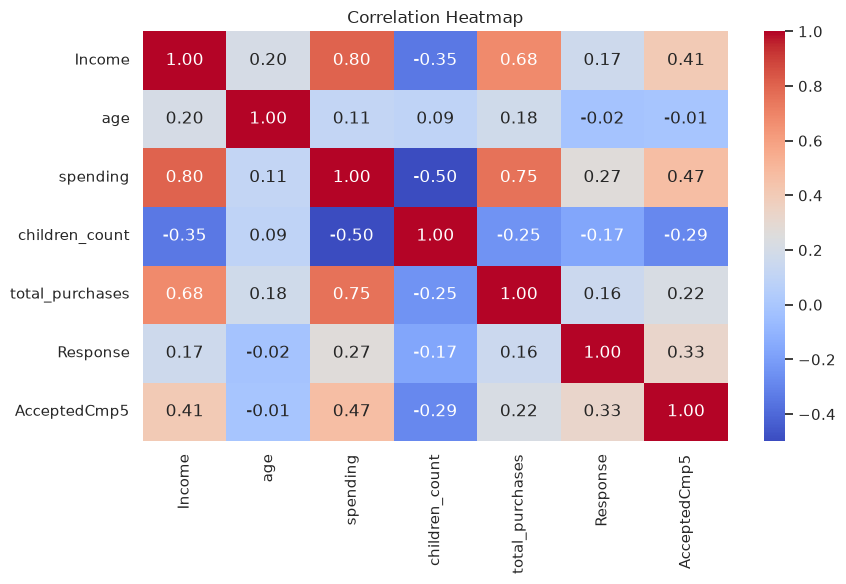

In [10]:
var_cor = [
    "Income", "age", "spending", "children_count",
    "total_purchases", "Response", "AcceptedCmp5"
]

correlation_matrix = new_data[var_cor].corr()
display(correlation_matrix)

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Hypothesis Testing

In [11]:
# H0: Mean spending is equal for customers with children and customers without children.
# H1: Mean spending differs between these two groups.
spending_with_children = new_data.loc[new_data["has_children"] == 1, "spending"].dropna()
spending_without_children = new_data.loc[new_data["has_children"] == 0, "spending"].dropna()

t_statistic, p_value = stats.ttest_ind(
    spending_with_children,
    spending_without_children,
    equal_var=False
)

print("H0: Mean spending is equal for customers with and without children.")
print("H1: Mean spending differs for customers with and without children.")
print(f"t-statistic: {t_statistic:.4f}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: Reject H0 at the 0.05 significance level.")
else:
    print("Result: Fail to reject H0 at the 0.05 significance level.")

H0: Mean spending is equal for customers with and without children.
H1: Mean spending differs for customers with and without children.
t-statistic: -25.0732
p-value: 0.000000
Result: Reject H0 at the 0.05 significance level.


## 9. Visualization

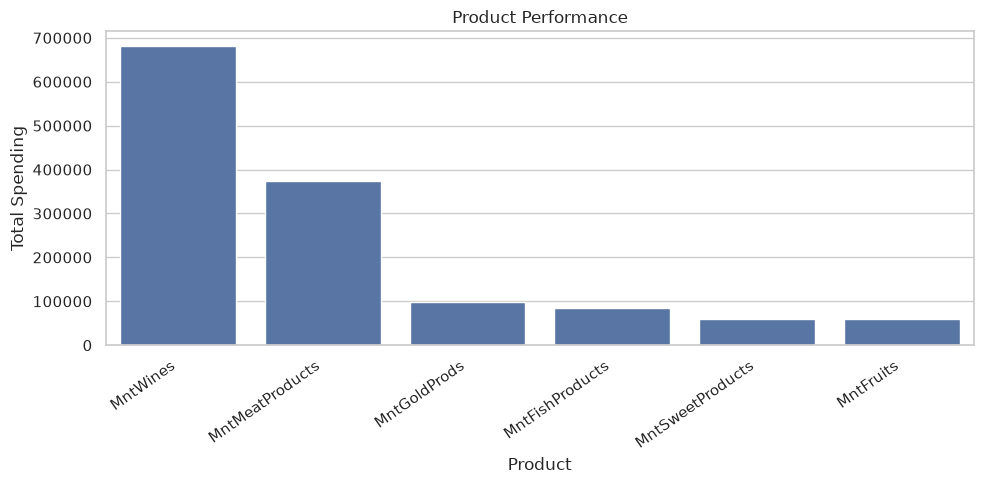

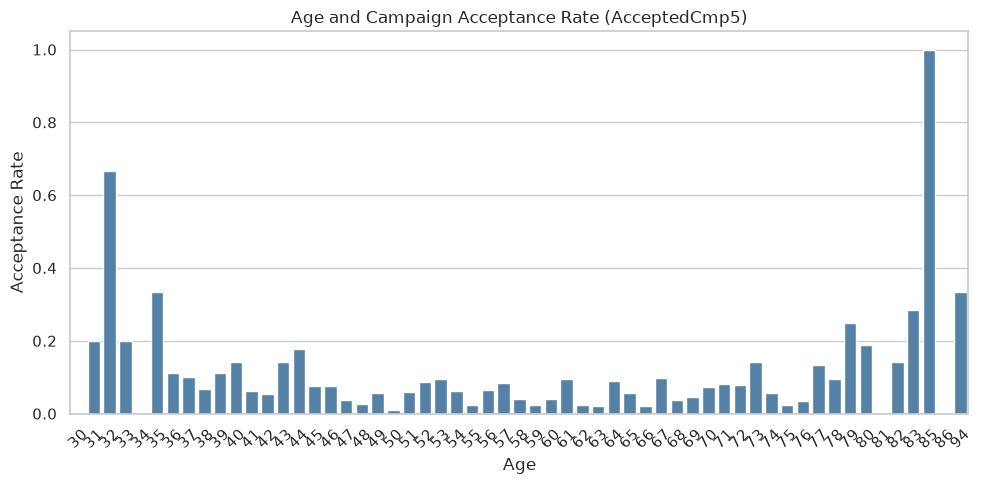

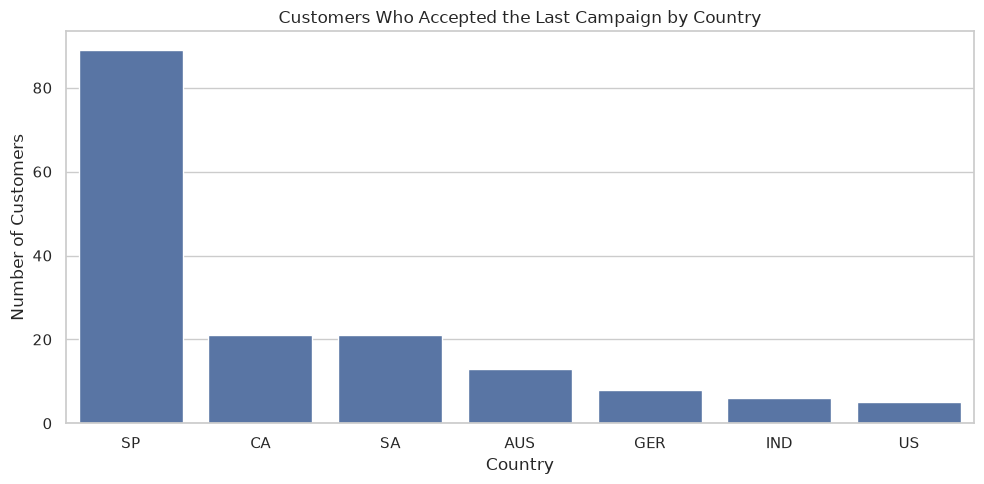

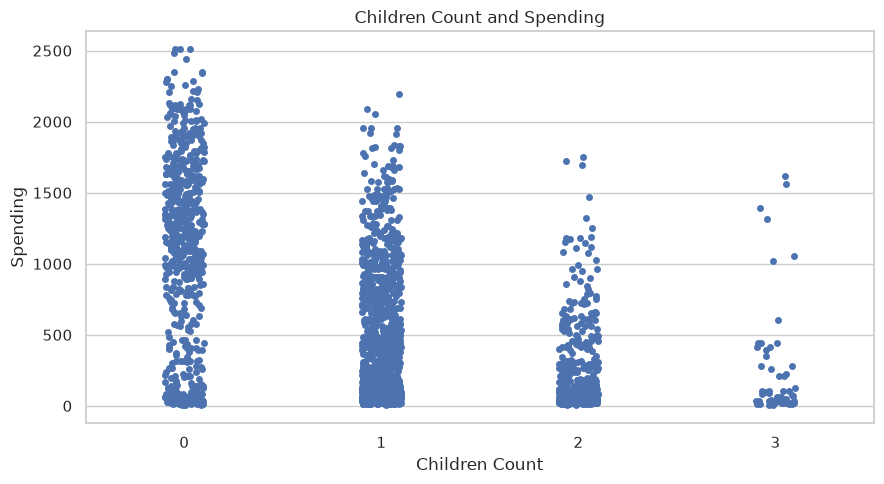

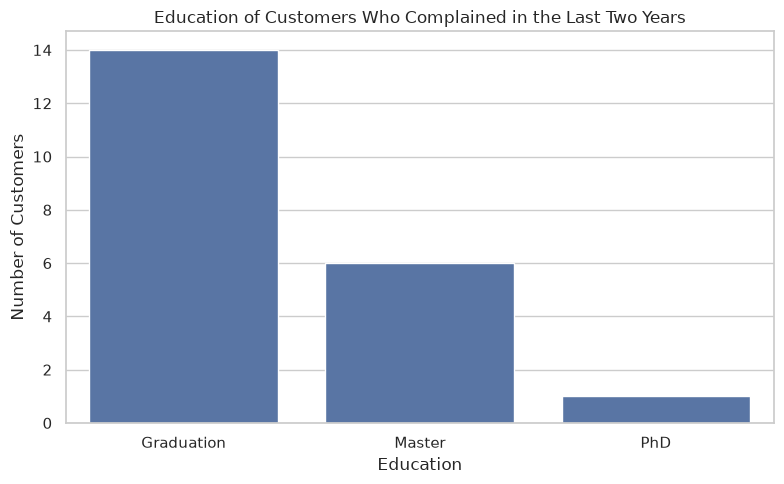

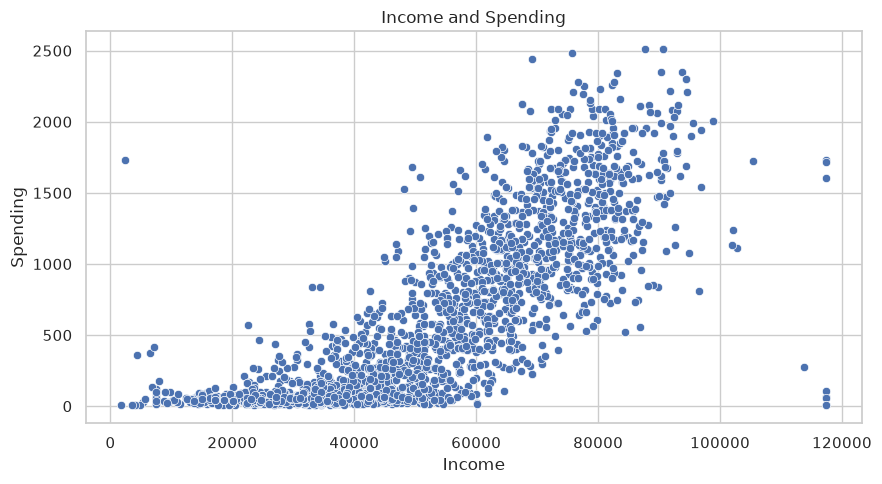

In [12]:
# Product performance (prod_data) using a bar plot.
product_columns = [
    "MntWines", "MntFruits", "MntMeatProducts",
    "MntFishProducts", "MntSweetProducts", "MntGoldProds"
]
prod_data = data[product_columns].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=prod_data.index, y=prod_data.values)
plt.title("Product Performance")
plt.xlabel("Product")
plt.ylabel("Total Spending")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Relationship between age and campaign acceptance rate (acceptedcmp5).
age_campaign = data.groupby("age", as_index=False)["AcceptedCmp5"].mean()
plt.figure(figsize=(10, 5))
sns.barplot(data=age_campaign, x="age", y="AcceptedCmp5", color="steelblue")
plt.title("Age and Campaign Acceptance Rate (AcceptedCmp5)")
plt.xlabel("Age")
plt.ylabel("Acceptance Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Country with the most customers who accepted the last campaign.
country_acceptance = data.loc[data["AcceptedCmp5"] == 1].groupby("Country").size().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=country_acceptance.index, y=country_acceptance.values)
plt.title("Customers Who Accepted the Last Campaign by Country")
plt.xlabel("Country")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Relationship between children_count and spending.
plt.figure(figsize=(9, 5))
sns.stripplot(data=data, x="children_count", y="spending", jitter=True)
plt.title("Children Count and Spending")
plt.xlabel("Children Count")
plt.ylabel("Spending")
plt.tight_layout()
plt.show()

# Educational background of customers who complained in the last two years.
complaint_education = data.loc[data["Complain"] == 1, "Education"].value_counts()
# Use original category names for display from the source data.
education_names = {0: "Basic", 1: "Graduation", 2: "Master", 3: "PhD"}
complaint_education.index = [education_names.get(x, str(x)) for x in complaint_education.index]
plt.figure(figsize=(8, 5))
sns.barplot(x=complaint_education.index, y=complaint_education.values)
plt.title("Education of Customers Who Complained in the Last Two Years")
plt.xlabel("Education")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Relationship between income and spending.
plt.figure(figsize=(9, 5))
sns.scatterplot(data=data, x="Income", y="spending")
plt.title("Income and Spending")
plt.xlabel("Income")
plt.ylabel("Spending")
plt.tight_layout()
plt.show()